In [72]:
import pandas as pd
import numpy as np
import seaborn as sns
import umap
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from sklearn import preprocessing
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN

sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})
combined_augmented_data = pd.read_csv("/home/surface-lab/variant_detection_codebase/Embedded_FS/combined_augmented_data.csv")

# Define x_train as just the cab values
colnames = combined_augmented_data.columns
cab_fluorescence_vals = combined_augmented_data[colnames[3:len(colnames)]]

target_vector_labels = combined_augmented_data['target_vector']
target_vector_vals = np.unique(target_vector_labels)

# Data needs to be centered and scaled with replicate and Conc. removed for now
simple_scaler = preprocessing.StandardScaler().fit(cab_fluorescence_vals)
normalized_cab_fluorescence = simple_scaler.transform(cab_fluorescence_vals)

# Obtain only values from concentrations greater than 0.1 ng/ml, get y_labels and scale
# This removes higher levels values
trimmed_augmented_data = combined_augmented_data[combined_augmented_data['Conc.'] > 0.1]
trimmed_data_y_labels = trimmed_augmented_data['target_vector']
trimmed_cab_fluorescence_vals = trimmed_augmented_data[colnames[3:len(colnames)]]
trimmed_normalized_cab_fluorescence = preprocessing.StandardScaler().fit_transform(trimmed_cab_fluorescence_vals)

# Only obtain values with concentrations between 0.1 and 100 to remove some of the higher leve
medium_trimmed_augmented_data = trimmed_augmented_data[(combined_augmented_data['Conc.'] > 0.1) & (combined_augmented_data['Conc.'] <= 100)]
medium_trimmed_data_y_labels = medium_trimmed_augmented_data['target_vector']
medium_trimmed_cab_fluorescence = medium_trimmed_augmented_data[colnames[3:len(colnames)]]
medium_trimmed_normalize_cab_fluorescence = preprocessing.StandardScaler().fit_transform(medium_trimmed_cab_fluorescence)

# sns.pairplot(trimmed_augmented_data.drop(["Replicate", "Conc."], axis=1), hue='target_vector')

/tmp/ipykernel_11957/3116337166.py:34: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  medium_trimmed_augmented_data = trimmed_augmented_data[(combined_augmented_data['Conc.'] > 0.1) & (combined_augmented_data['Conc.'] <= 100)]


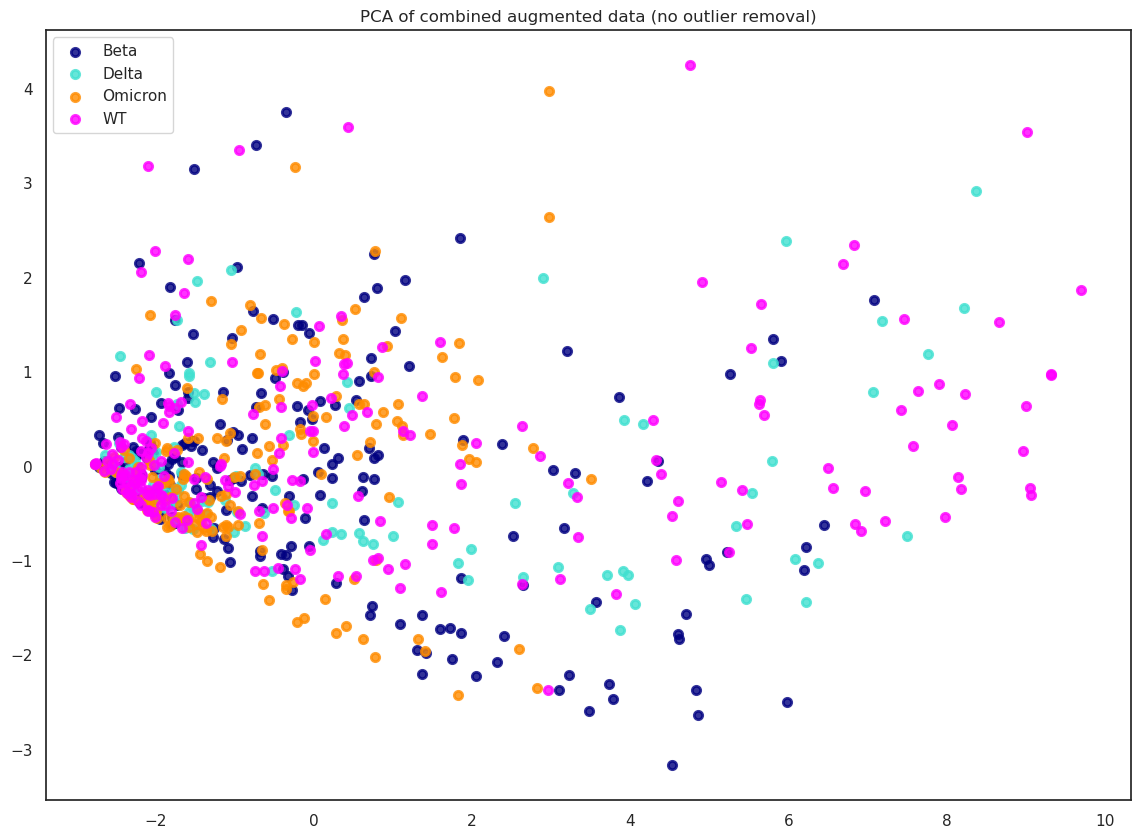

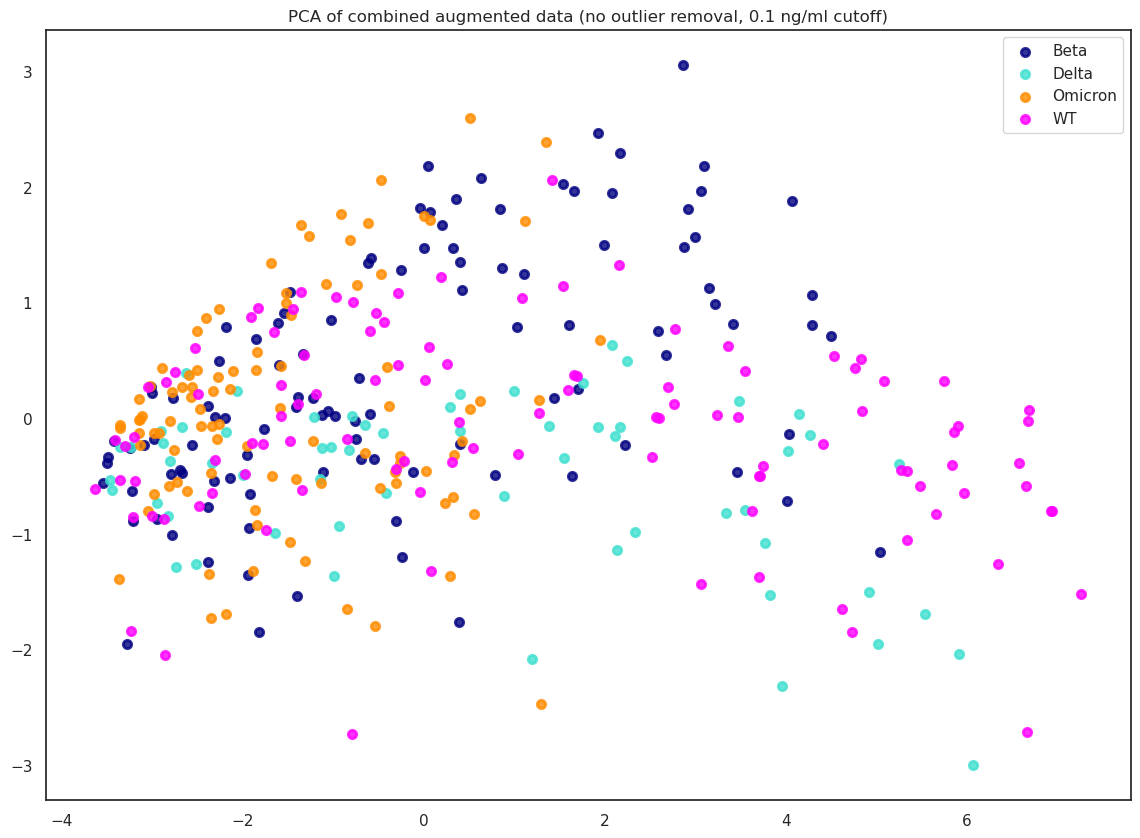

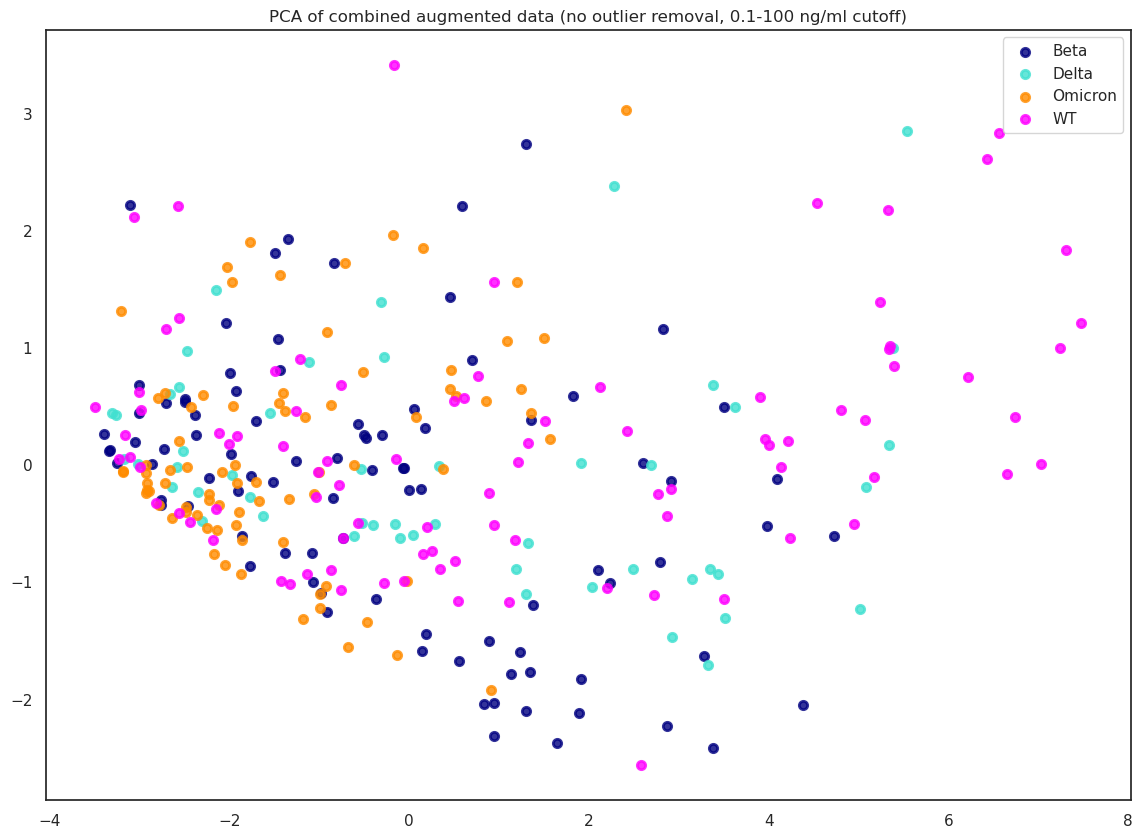

In [70]:
# PCA
def plot_pca(scaled_dataset,
        colors = ["navy", "turquoise", "darkorange", 'magenta'],
        true_labels = target_vector_labels,
        plot_title = "PCA of combined augmented data (no outlier removal)"
    ):
    target_vals = np.unique(true_labels)
    pca_mod = PCA(n_components=2)
    pca_decomp = pca_mod.fit_transform(scaled_dataset)

    plt.figure()
    lw = 2

    for color, i, target_name in zip(colors, target_vals, true_labels):
        plt.scatter(
            pca_decomp[true_labels == i, 0],
            pca_decomp[true_labels == i, 1],
            color = color, alpha = 0.8,
            lw=lw, label = i
        )
    plt.legend(loc="best", shadow=False, scatterpoints=1)
    plt.title(plot_title)
    plt.show()


plot_pca(normalized_cab_fluorescence,
         plot_title = "PCA of combined augmented data (no outlier removal)")

plot_pca(trimmed_normalized_cab_fluorescence,
         true_labels=trimmed_data_y_labels,
         plot_title = "PCA of combined augmented data (no outlier removal, 0.1 ng/ml cutoff)")

plot_pca(medium_trimmed_normalize_cab_fluorescence,
         true_labels = medium_trimmed_data_y_labels,
         plot_title= "PCA of combined augmented data (no outlier removal, 0.1-100 ng/ml cutoff)")

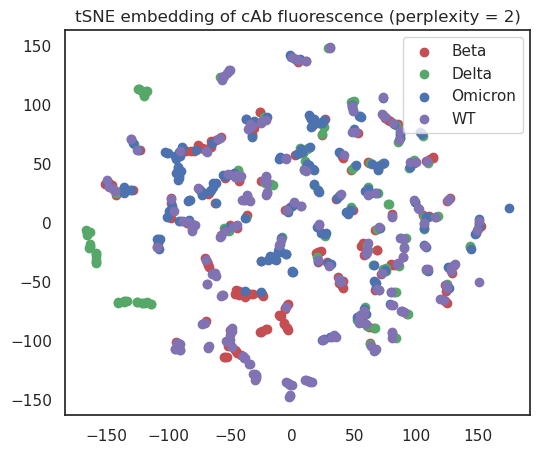

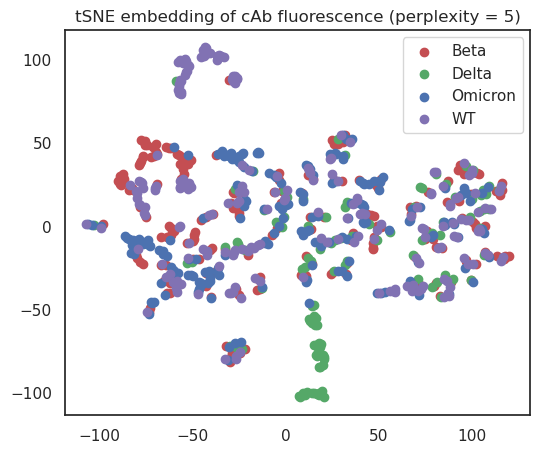

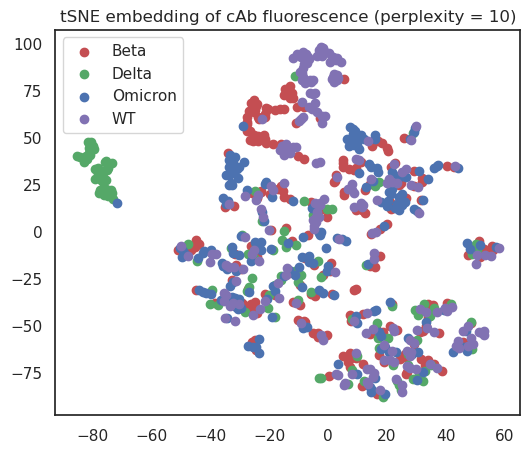

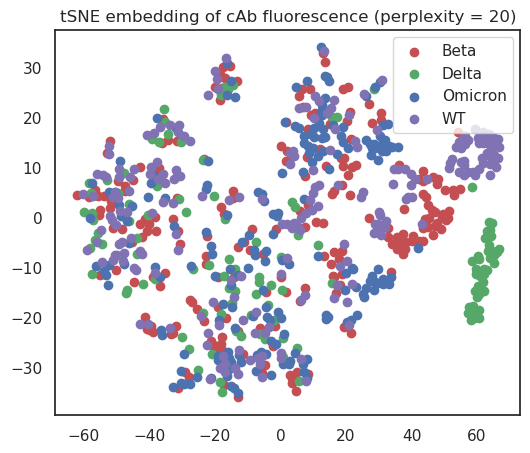

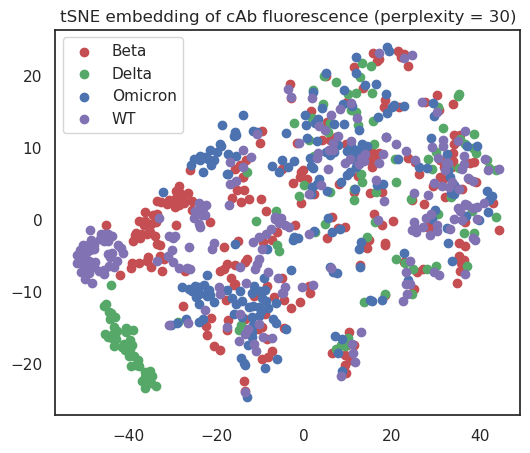

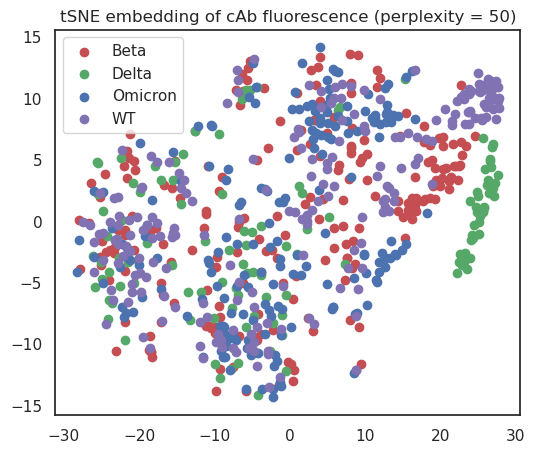

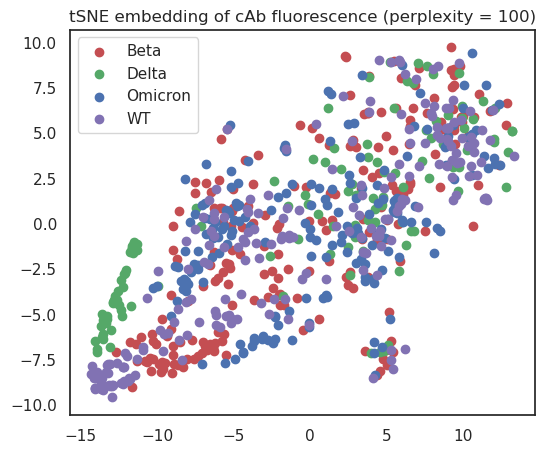

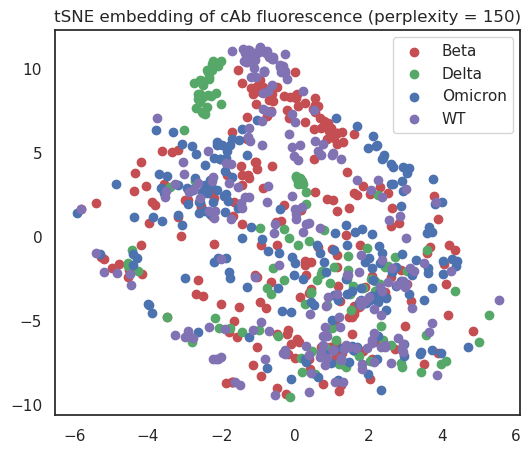

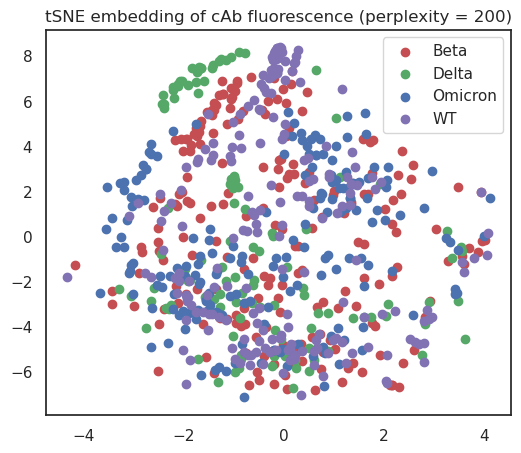

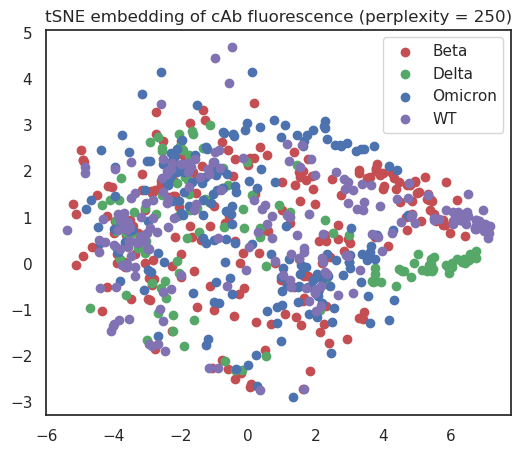

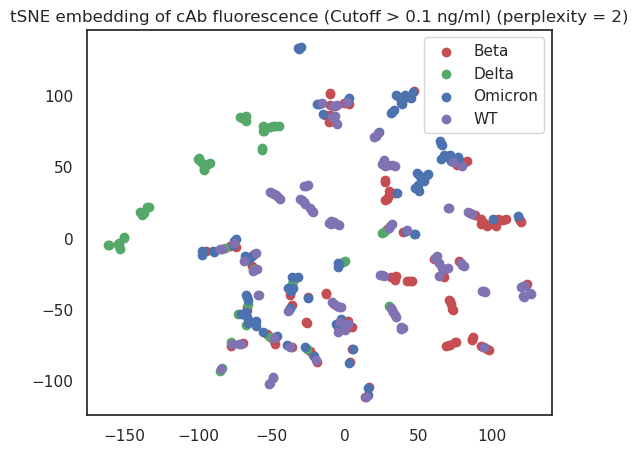

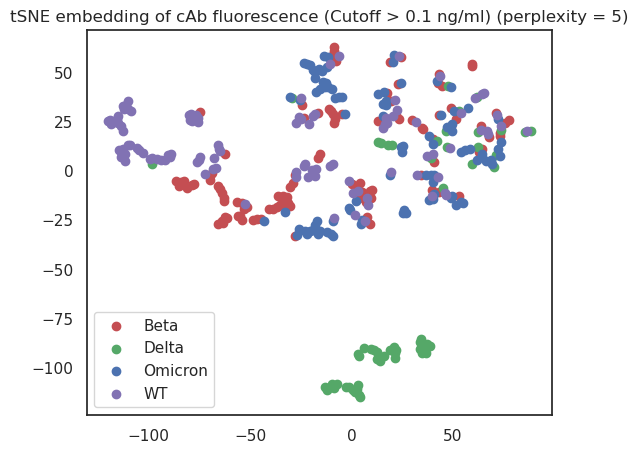

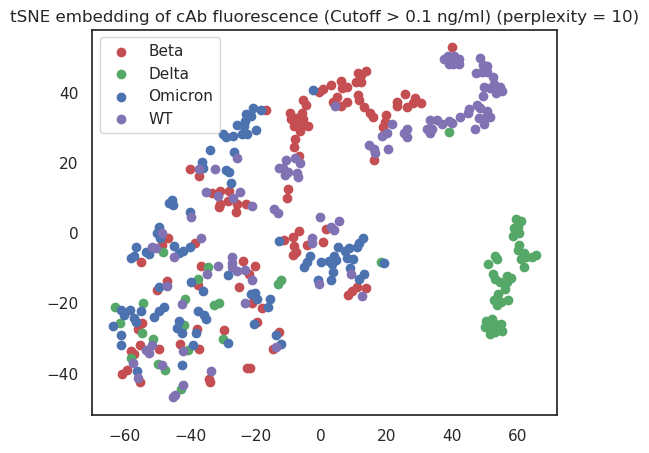

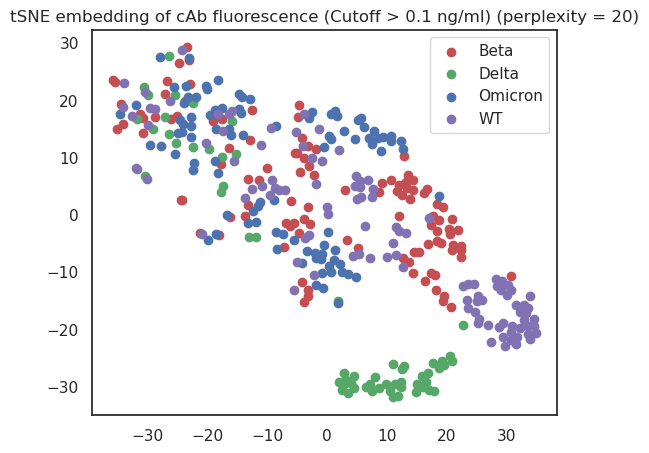

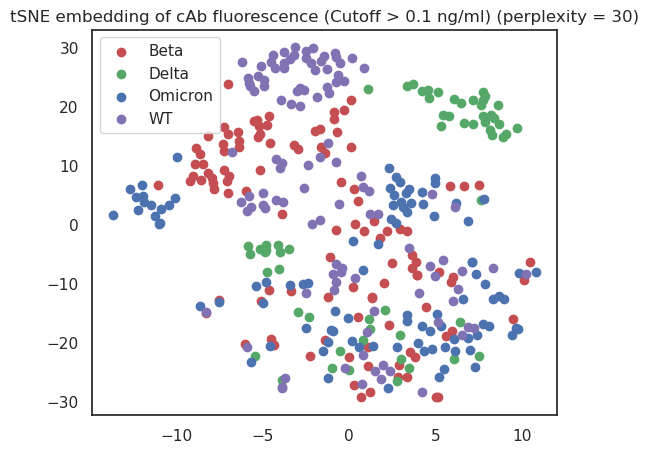

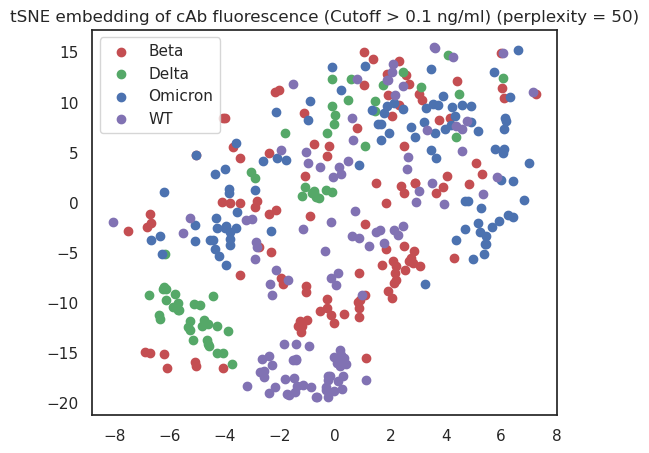

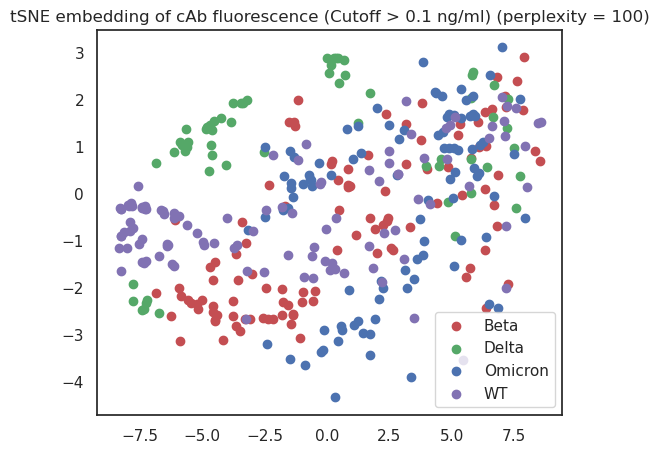

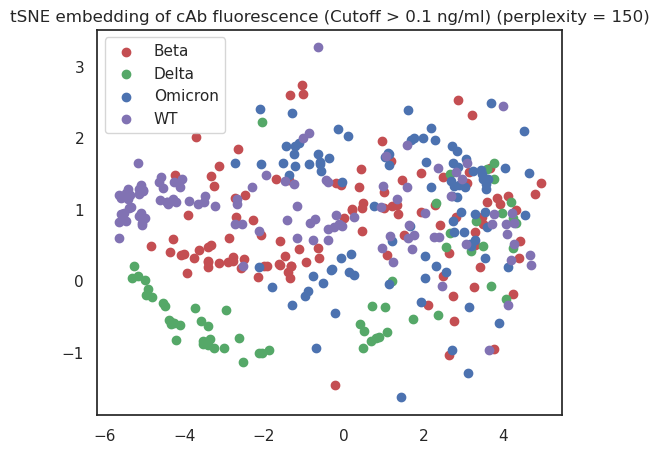

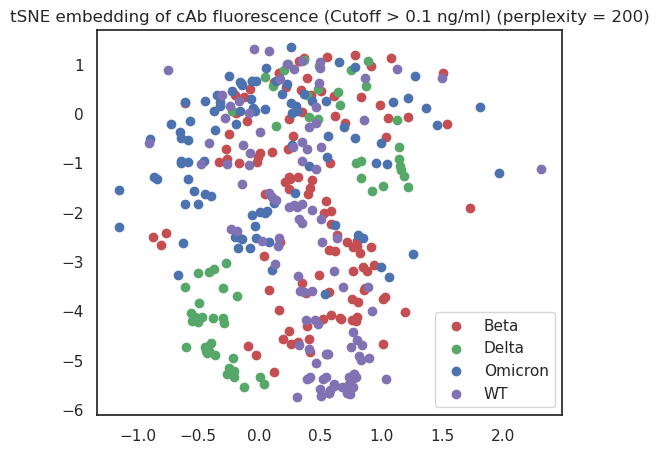

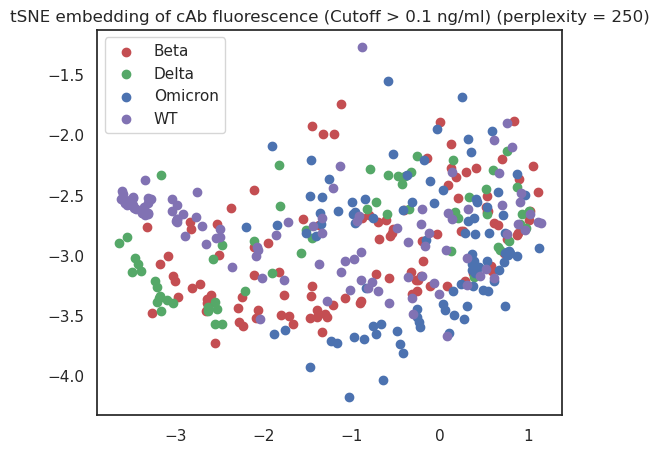

In [66]:
# tSNE
def tsne_opt(scaled_dataset,
             true_labels,
             perplexity_vals = [5, 10, 25, 50], 
             n_iterations = 5000, 
             colors = ['r', 'g', 'b', 'm'],
             plot_title = 'tSNE embedding'):
    
    y_labs = true_labels
    y_vals = np.unique(true_labels)

    tSNE_mods = []
    for perp_val in perplexity_vals:
        plt_title = plot_title
        updated_plot_title = plt_title + f" (perplexity = {perp_val})"
        tsne_mod = TSNE(n_components = 2,
                                    learning_rate= 'auto',
                                    init = 'random',
                                    perplexity = perp_val,
                                    n_iter = n_iterations)
        
        tsne_embedded_fluorescence = tsne_mod.fit_transform(scaled_dataset)
        tSNE_mods.append(tsne_embedded_fluorescence)

        plt.figure(figsize=(6,5))

        for i, c, label in zip(y_vals, colors, y_labs):
            plt.scatter(
                tsne_embedded_fluorescence[y_labs == i, 0], 
                tsne_embedded_fluorescence[y_labs == i, 1], 
                c=c, label=i)
        plt.title(updated_plot_title)
        plt.legend()
        plt.show()

def tsne_opt2(scaled_dataset,
             true_labels,
             perplexity_vals = [5, 10, 25, 50], 
             n_iterations = 5000, 
             colors = ['r', 'g', 'b', 'm'],
             plot_title = 'tSNE embedding',
             subplot_dims):
    
    # Set up subplot (subplot dims should be provided as number of rows, cols in a tuple)
    fig, axs = plt.subplots(subplot_dims[0], subplot_dims[1], fig_size=(12,10))
    fig.suptitle(plot_title)
    
    y_labs = true_labels
    y_vals = np.unique(true_labels)

    tSNE_mods = []
    for perp_val in perplexity_vals:
        plt_title = plot_title
        updated_plot_title = plt_title + f" (perplexity = {perp_val})"
        tsne_mod = TSNE(n_components = 2,
                                    learning_rate= 'auto',
                                    init = 'random',
                                    perplexity = perp_val,
                                    n_iter = n_iterations)
        
        tsne_embedded_fluorescence = tsne_mod.fit_transform(scaled_dataset)
        tSNE_mods.append(tsne_embedded_fluorescence)

        plt.figure(figsize=(6,5))

        for i, c, label in zip(y_vals, colors, y_labs):
            plt.scatter(
                tsne_embedded_fluorescence[y_labs == i, 0], 
                tsne_embedded_fluorescence[y_labs == i, 1], 
                c=c, label=i)
        plt.title(updated_plot_title)
        plt.legend()
        plt.show()

tsne_opt2(scaled_dataset=normalized_cab_fluorescence,
         true_labels = target_vector_labels,
         perplexity_vals = [2, 5, 10, 20, 30, 50, 100, 150, 200, 250],
         plot_title='tSNE embedding of cAb fluorescence',
         subplot_dims = (2, 5))

tsne_opt(scaled_dataset=trimmed_normalized_cab_fluorescence,
         true_labels=trimmed_data_y_labels,
         perplexity_vals = [2, 5, 10, 20, 30, 50, 100, 150, 200, 250],
         plot_title='tSNE embedding of cAb fluorescence (Cutoff > 0.1 ng/ml)')

# tSNE with PCA scores as input to help reduce noise - pretty nondescript
# tsne_opt(scaled_dataset = augmented_data_pca,
#          true_labels = target_vector_labels,
#          perplexity_vals = [2, 5, 10, 20, 30, 50, 100, 150, 200, 250],
#          plot_title='tSNE embedding of cAb fluorescence PCA scores')

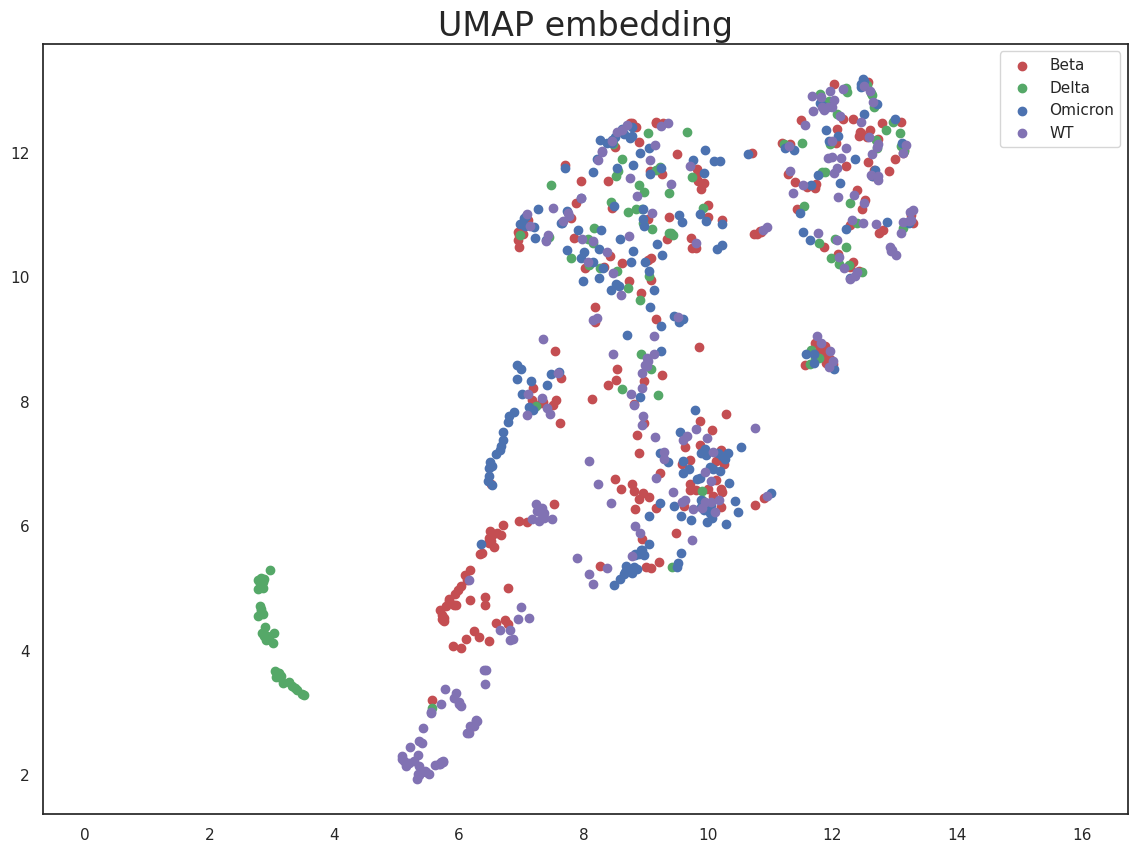

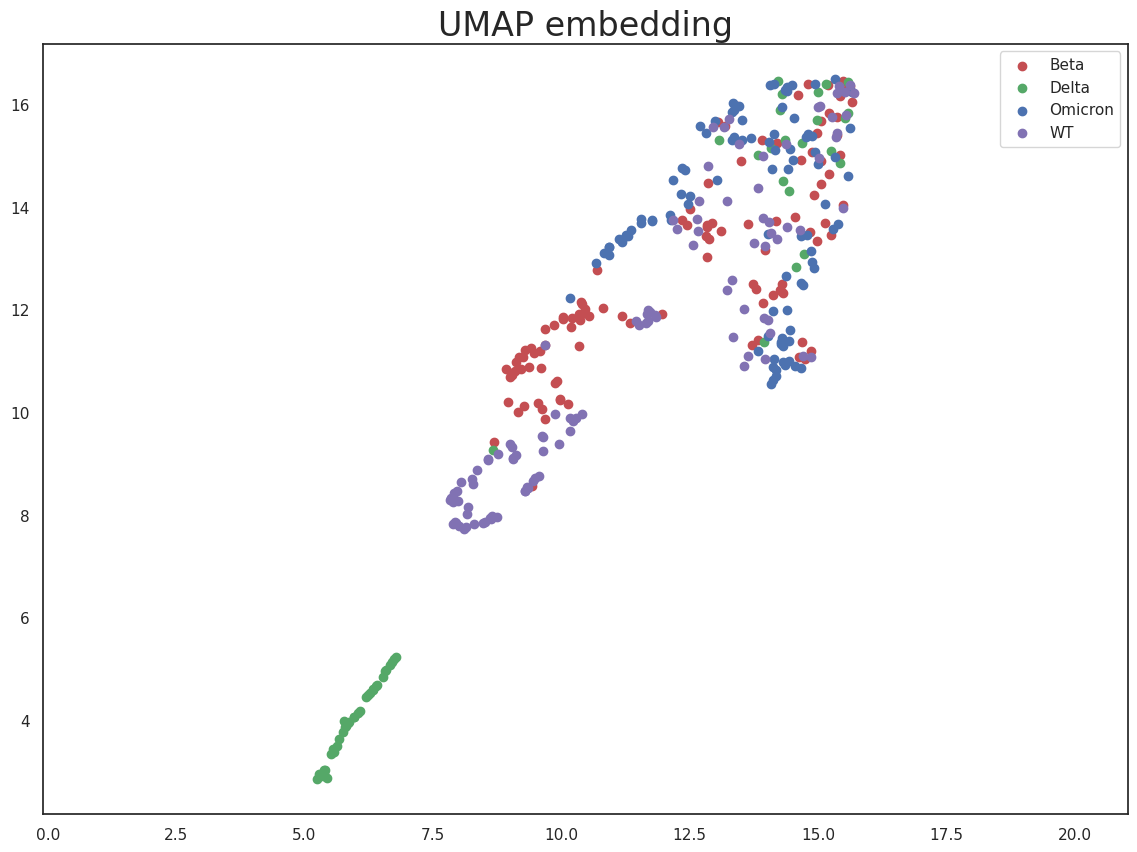

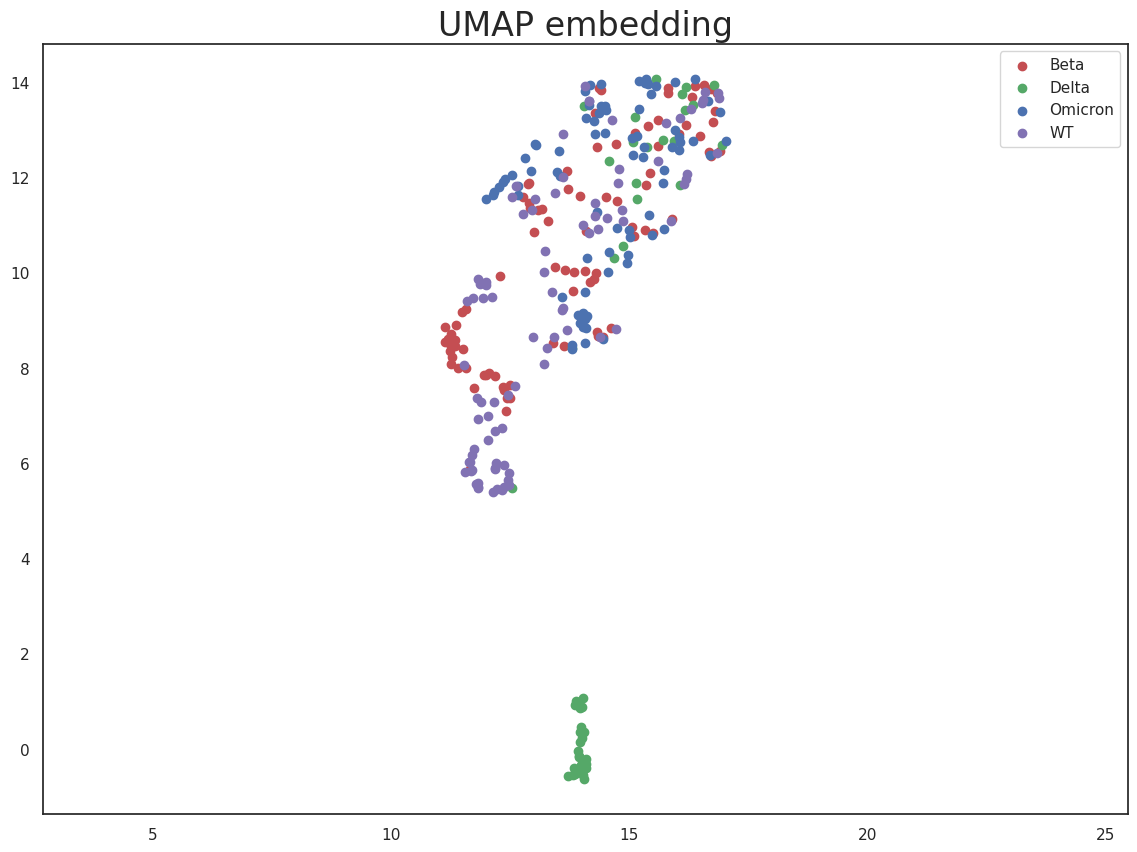

In [71]:
def umap_reducer(scaled_dataset,
                 true_y_labels,
                #  parameter_grid,
                 colors = ['r', 'g', 'b', 'm'],
                 plot_title = 'UMAP embedding'):
    
    y_labs = true_y_labels
    y_vals = np.unique(true_y_labels)

    reducer = umap.UMAP()
    umap_embedding = reducer.fit_transform(scaled_dataset)

    for i, c, label in zip(y_vals, colors, y_labs):
        plt.scatter(
            umap_embedding[y_labs == i, 0], 
            umap_embedding[y_labs == i, 1], 
            c=c, label=i)
    
    plt.legend()
    plt.gca().set_aspect('equal', 'datalim')
    plt.title(plot_title, fontsize=24)
    plt.show()



umap_reducer(normalized_cab_fluorescence,
             target_vector_labels
             )

umap_reducer(trimmed_normalized_cab_fluorescence,
             trimmed_data_y_labels
             )

umap_reducer(medium_trimmed_normalize_cab_fluorescence,
             medium_trimmed_data_y_labels
             )